# Part e: MNIST Classification

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import Functions as func
import Utils as utz
import NeuralNetworkClass as NN
SEED   = 2026
M      = 100      # minibatch-size
EPOCHS = 10

# Gridsearches takes time
RUN_GRIDSEARCH = True

## Data

In [11]:
# Load the data
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test,  y_test  = data["x_test"],  data["y_test"]

# Convert the 28x28 images into vectors with 784 values and scale them to [0, 1]
x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test  = x_test.reshape(len(x_test), -1) / 255.0

# Set aside 10,000 training images as the validation set
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train,
    y_train,
    test_size=10000,
    stratify=y_train,
    random_state=SEED
)

X_tr,  Y_tr  = x_tr,   utz.one_hot(y_tr)
X_val, Y_val = x_val,  utz.one_hot(y_val)
X_te,  Y_te  = x_test, utz.one_hot(y_test)

# Check the shapes and class distribution
print(X_tr.shape, Y_tr.shape, X_val.shape, X_te.shape)
print(np.bincount(y_tr))

(50000, 784) (50000, 10) (10000, 784) (10000, 784)
[4936 5618 4965 5109 4868 4517 4932 5221 4876 4958]


## Functions for grid search and heatmaps

In [12]:
def accuracy(model, X, y):
    return np.mean(np.argmax(model.predict(X), axis=1) == y)


def grid_search(nn, X_tr, Y_tr, y_tr, X_val, y_val, gammas, lambdas):
    """Train nn for all combinations of gamma and lambda.
    Return validation and training accuracy."""
    val_acc   = np.zeros((len(gammas), len(lambdas)))
    train_acc = np.zeros((len(gammas), len(lambdas)))
    for i, g in enumerate(gammas):
        for j, l in enumerate(lambdas):
            nn.change_seed(SEED)
            nn.optimizer("ADAM")
            nn.learning_rate(g)
            nn.add_penalty(l, "L2")
            nn.train(X_tr, Y_tr, epochs=EPOCHS, M=M)
            val_acc[i, j]   = accuracy(nn, X_val, y_val)
            train_acc[i, j] = accuracy(nn, X_tr, y_tr)
            print(f"γ={g:.0e}  λ={l:.0e}  val acc={val_acc[i, j]:.4f}")
    return val_acc, train_acc


def plot_heatmap_tv(val, train, xlab, ylab, xname, yname, title, filename, vmin=0.85):
    """Heatmap where the color represents validation accuracy.
    Each cell shows validation accuracy on top and training accuracy in parentheses below."""
    labels = np.array([[f"{v:.3f}\n({t:.3f})" for v, t in zip(rv, rt)]
                       for rv, rt in zip(val, train)])

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(val, vmin=vmin, annot=labels, fmt="", cmap="YlGnBu",
                xticklabels=xlab, yticklabels=ylab,
                cbar_kws={"label": "Validation accuracy"}, ax=ax)
    ax.set_xlabel(xname)
    ax.set_ylabel(yname)
    ax.set_title(title + ": validation (training)")
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()


gammas  = [1e-4, 1e-3, 1e-2, 1e-1]
lambdas = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]

gam_lab = [f"{g:.0e}" for g in gammas]     # Labels for the heatmap
lam_lab = [f"{l:.0e}" for l in lambdas]

## 1. Logistic regression: $\gamma$ og $\lambda$

Logistic regression is equivalent to a network with no hidden layers and a softmax output.

γ=1e-04  λ=0e+00  val acc=0.9016
γ=1e-04  λ=1e-05  val acc=0.9016
γ=1e-04  λ=1e-04  val acc=0.9013
γ=1e-04  λ=1e-03  val acc=0.8998
γ=1e-04  λ=1e-02  val acc=0.8895
γ=1e-03  λ=0e+00  val acc=0.9262
γ=1e-03  λ=1e-05  val acc=0.9258
γ=1e-03  λ=1e-04  val acc=0.9236
γ=1e-03  λ=1e-03  val acc=0.9178
γ=1e-03  λ=1e-02  val acc=0.8956
γ=1e-02  λ=0e+00  val acc=0.9085
γ=1e-02  λ=1e-05  val acc=0.9093
γ=1e-02  λ=1e-04  val acc=0.9034
γ=1e-02  λ=1e-03  val acc=0.8930
γ=1e-02  λ=1e-02  val acc=0.8692
γ=1e-01  λ=0e+00  val acc=0.8750
γ=1e-01  λ=1e-05  val acc=0.8661
γ=1e-01  λ=1e-04  val acc=0.8243
γ=1e-01  λ=1e-03  val acc=0.8427
γ=1e-01  λ=1e-02  val acc=0.7788


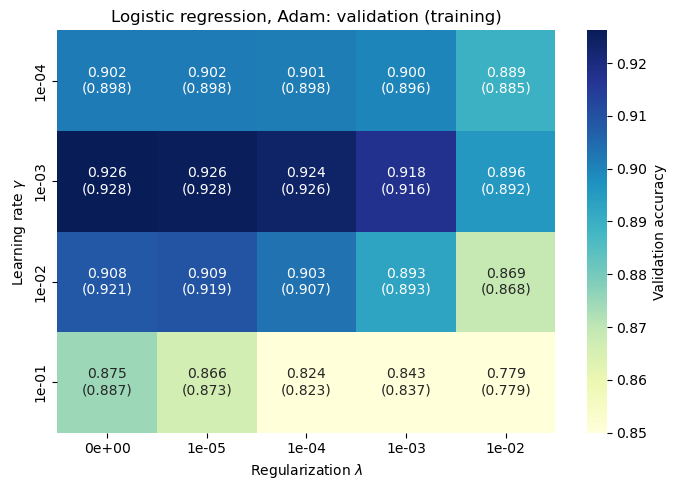

In [13]:
nn_lr = NN.NeuralNetwork(
    network_input_size = X_tr.shape[1],
    layer_output_sizes = [10],
    activation_funcs   = [func.softmax],
    activation_ders    = [None],
    cost_fun           = func.cross_entropy,
    cost_der           = None,
    classification     = True       # the gradient of softmax + cross-entropy is computed directly
)

if RUN_GRIDSEARCH:                  
    acc_lr, train_acc_lr = grid_search(nn_lr, X_tr, Y_tr, y_tr, X_val, y_val, gammas, lambdas)
    np.save("acc.npy", acc_lr)
    np.save("train_acc_lr.npy", train_acc_lr)
else:
    acc_lr       = np.load("acc.npy")
    train_acc_lr = np.load("train_acc_lr.npy")

plot_heatmap_tv(acc_lr, train_acc_lr, lam_lab, gam_lab,
                r"Regularization $\lambda$", r"Learning rate $\gamma$",
                "Logistic regression, Adam", "baseline_heat_tv.pdf", vmin=0.85)

## 2. One hidden layer (100 nodes, ReLU): $\gamma$ og $\lambda$

The best combination from this search is used in the remaining grid searches.

γ=1e-04  λ=0e+00  val acc=0.9396
γ=1e-04  λ=1e-05  val acc=0.9394
γ=1e-04  λ=1e-04  val acc=0.9392
γ=1e-04  λ=1e-03  val acc=0.9353
γ=1e-04  λ=1e-02  val acc=0.9118
γ=1e-03  λ=0e+00  val acc=0.9746
γ=1e-03  λ=1e-05  val acc=0.9745
γ=1e-03  λ=1e-04  val acc=0.9751
γ=1e-03  λ=1e-03  val acc=0.9655
γ=1e-03  λ=1e-02  val acc=0.9106
γ=1e-02  λ=0e+00  val acc=0.9637
γ=1e-02  λ=1e-05  val acc=0.9666
γ=1e-02  λ=1e-04  val acc=0.9581
γ=1e-02  λ=1e-03  val acc=0.9479
γ=1e-02  λ=1e-02  val acc=0.8854


/Users/slitenpakistaner/Documents/Skole/FYS-STK4155/Projects/Project 2/FYS-STK4155-Project-2/Code/Functions.py:45: RuntimeWarning: divide by zero encountered in log
  return np.mean(np.sum(-target*np.log(predict), axis=1))
/Users/slitenpakistaner/Documents/Skole/FYS-STK4155/Projects/Project 2/FYS-STK4155-Project-2/Code/Functions.py:45: RuntimeWarning: invalid value encountered in multiply
  return np.mean(np.sum(-target*np.log(predict), axis=1))


γ=1e-01  λ=0e+00  val acc=0.7307
γ=1e-01  λ=1e-05  val acc=0.8123
γ=1e-01  λ=1e-04  val acc=0.8467
γ=1e-01  λ=1e-03  val acc=0.8077
γ=1e-01  λ=1e-02  val acc=0.7181


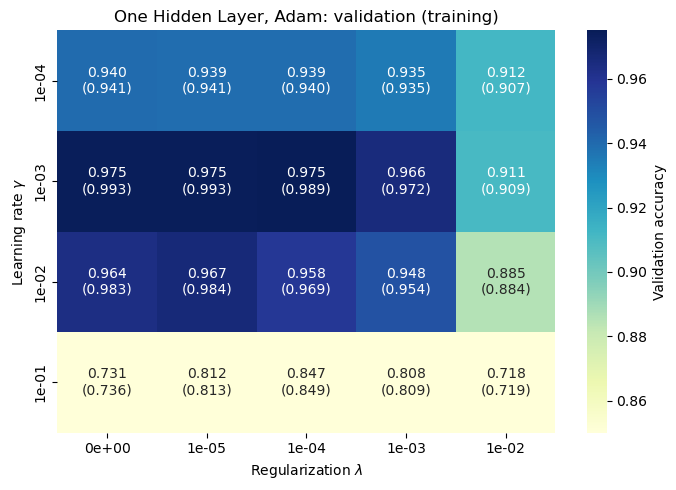

Best: γ = 0.001, λ = 0.0001, val acc = 0.9751


In [14]:
nn1 = NN.NeuralNetwork(
    network_input_size = X_tr.shape[1],
    layer_output_sizes = [100, 10],         # one hidden layer with 100 nodes, 10 outputs
    activation_funcs   = [func.ReLU, func.softmax],
    activation_ders    = [func.ReLU_der, None],
    cost_fun           = func.cross_entropy,
    cost_der           = None,
    classification     = True
)

if RUN_GRIDSEARCH:                  
    acc1, train_acc1 = grid_search(nn1, X_tr, Y_tr, y_tr, X_val, y_val, gammas, lambdas)
    np.save("onehidden_acc.npy", acc1)
    np.save("onehidden_train_acc.npy", train_acc1)
else:
    acc1       = np.load("onehidden_acc.npy")
    train_acc1 = np.load("onehidden_train_acc.npy")

plot_heatmap_tv(acc1, train_acc1, lam_lab, gam_lab,
                r"Regularization $\lambda$", r"Learning rate $\gamma$",
                "One Hidden Layer, Adam", "1Hidden_heat_tv.pdf", vmin=0.85)

i, j = np.unravel_index(np.argmax(acc1), acc1.shape)
g_best, l_best = gammas[i], lambdas[j]     # Check that these are indeed the values discussed in the text
print(f"Best: γ = {g_best}, λ = {l_best}, val acc = {acc1[i, j]:.4f}")

## 3. Activation function and width (one hidden layer)

Using $\gamma$ and $\lambda$ from step 2.

In [15]:
activations = {
    "sigmoid":    (func.sigmoid,    func.sigmoid_der),
    "ReLU":       (func.ReLU,       func.ReLU_der),
    "Leaky ReLU": (func.leaky_ReLU, func.leaky_ReLU_der),
}
widths = [16, 32, 64, 128, 256]     # number of nodes in the hidden layer

if RUN_GRIDSEARCH:                  # NOTE! Computationally intensive
    val_acc_act   = np.zeros((len(activations), len(widths)))
    train_acc_act = np.zeros((len(activations), len(widths)))

    for a, (name, (f, f_der)) in enumerate(activations.items()):
        for k, w in enumerate(widths):
            net = NN.NeuralNetwork(X_tr.shape[1], [w, 10], [f, func.softmax], [f_der, None],
                                   func.cross_entropy, None, classification=True)
            net.optimizer("ADAM")
            net.learning_rate(g_best)
            net.add_penalty(l_best, "L2")
            net.train(X_tr, Y_tr, epochs=EPOCHS, M=M)
            val_acc_act[a, k]   = accuracy(net, X_val, y_val)
            train_acc_act[a, k] = accuracy(net, X_tr, y_tr)
            print(f"{name:10s}  {w:4d} noder  train {train_acc_act[a, k]:.4f}  val {val_acc_act[a, k]:.4f}")

    np.save("act_width_val.npy", val_acc_act)
    np.save("act_width_train.npy", train_acc_act)
else:
    val_acc_act   = np.load("act_width_val.npy")
    train_acc_act = np.load("act_width_train.npy")

plot_heatmap_tv(val_acc_act, train_acc_act, widths, list(activations.keys()),
                "Width", "Activation function",
                "Activations vs Widths, 1 Hidden layer, Adam", "actVSWidth_heat_tv.pdf", vmin=0.93)

sigmoid       16 noder  train 0.9375  val 0.9330
sigmoid       32 noder  train 0.9531  val 0.9471
sigmoid       64 noder  train 0.9626  val 0.9561
sigmoid      128 noder  train 0.9673  val 0.9606
sigmoid      256 noder  train 0.9709  val 0.9636
ReLU          16 noder  train 0.9531  val 0.9474
ReLU          32 noder  train 0.9730  val 0.9628
ReLU          64 noder  train 0.9848  val 0.9714
ReLU         128 noder  train 0.9899  val 0.9762
ReLU         256 noder  train 0.9943  val 0.9785
Leaky ReLU    16 noder  train 0.9527  val 0.9481
Leaky ReLU    32 noder  train 0.9713  val 0.9619
Leaky ReLU    64 noder  train 0.9834  val 0.9706


KeyboardInterrupt: 

## 4. Depth and width (Leaky ReLU)

All hidden layers have the same width. Still using $\gamma$ and $\lambda$ from step 2.

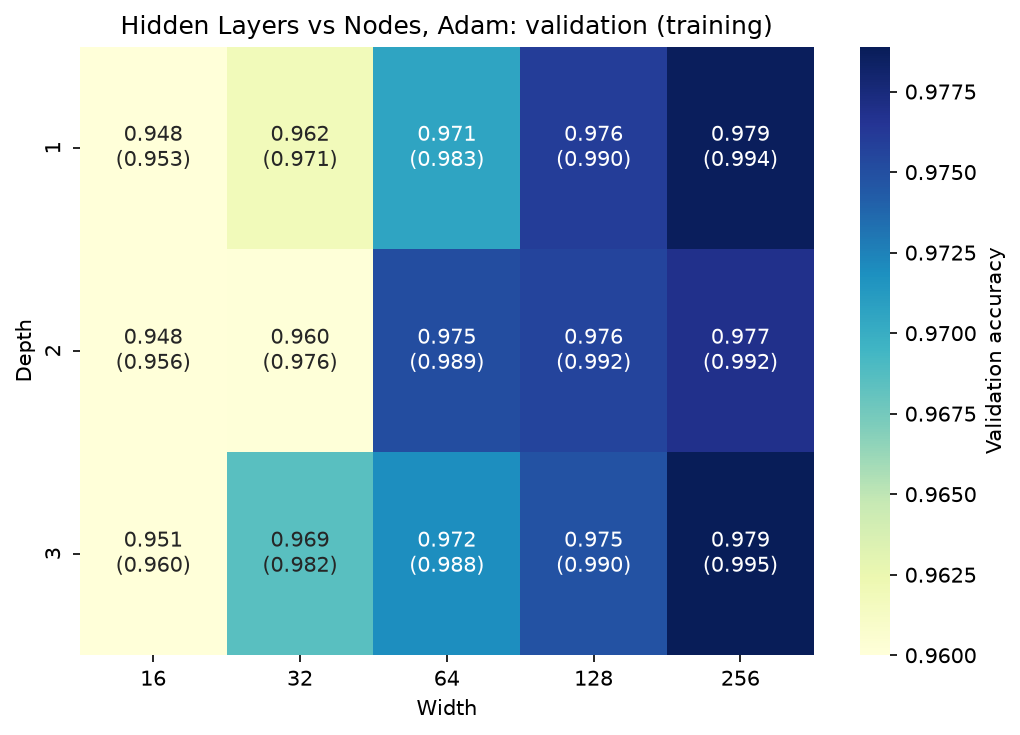

In [ ]:
f, f_der = func.leaky_ReLU, func.leaky_ReLU_der
depths = [1, 2, 3]                  # number of hidden layers

if RUN_GRIDSEARCH:                  # NOTE! Computationally intensive
    val_acc_d   = np.zeros((len(depths), len(widths)))
    train_acc_d = np.zeros((len(depths), len(widths)))

    for d, L in enumerate(depths):
        for k, w in enumerate(widths):
            net = NN.NeuralNetwork(
                X_tr.shape[1],
                [w] * L + [10],             # e.g. [w, w, 10] for two hidden layers
                [f] * L + [func.softmax],
                [f_der] * L + [None],
                func.cross_entropy,
                None,
                classification=True
            )
            net.optimizer("ADAM")
            net.learning_rate(g_best)
            net.add_penalty(l_best, "L2")
            net.train(X_tr, Y_tr, epochs=EPOCHS, M=M)
            val_acc_d[d, k]   = accuracy(net, X_val, y_val)
            train_acc_d[d, k] = accuracy(net, X_tr, y_tr)
            print(f"{L} lag × {w:3d} noder  train {train_acc_d[d, k]:.4f}  val {val_acc_d[d, k]:.4f}")

    np.save("depth_width_val.npy", val_acc_d)
    np.save("depth_width_train.npy", train_acc_d)
else:
    val_acc_d   = np.load("depth_width_val.npy")
    train_acc_d = np.load("depth_width_train.npy")

plot_heatmap_tv(val_acc_d, train_acc_d, widths, depths,
                "Width", "Depth",
                "Hidden Layers vs Nodes, Adam", "HidLayvsNodes_heat_tv.pdf", vmin=0.96)

## Summary of the grid searches

In [ ]:
grids = [
    ("Logistic regression",  acc_lr,      gammas,                   lambdas),
    ("1 hidden layer",         acc1,        gammas,                   lambdas),
    ("Activation vs. width", val_acc_act, list(activations.keys()), widths),
    ("Depth vs. width",      val_acc_d,   depths,                   widths),
]

print(f"{'Gridsearch':22s} {'Rad':>10s} {'Kolonne':>8s} {'Val acc':>8s}")
for name, A, row_lab, col_lab in grids:
    i, j = np.unravel_index(np.argmax(A), A.shape)
    print(f"{name:22s} {str(row_lab[i]):>10s} {str(col_lab[j]):>8s} {A[i, j]:8.4f}")

Gridsearch                    Rad  Kolonne  Val acc
Logistisk regresjon         0.001      0.0   0.9262
1 skjult lag                0.001   0.0001   0.9751
Aktivering vs bredde   Leaky ReLU      256   0.9787
Dybde vs bredde                 3      256   0.9789


In [ ]:
X_full = x_train
Y_full = utz.one_hot(y_train)

def build_and_train(sizes, acts, ders, gamma, lam, X, Y):
    net = NN.NeuralNetwork(X.shape[1], sizes, acts, ders,
                           func.cross_entropy, None, classification=True)
    net.change_seed(SEED)
    net.optimizer("ADAM")
    net.learning_rate(gamma)
    net.add_penalty(lam, "L2")
    net.train(X, Y, epochs=EPOCHS, M=M)
    return net


final_models = {
    "Logistic regression": (
        [10], [func.softmax], [None], 1e-3, 1e-5),    
    "1 x 256, Leaky ReLU": (
        [256, 10], [func.leaky_ReLU, func.softmax],
        [func.leaky_ReLU_der, None], g_best, l_best),
    "2 x 256, Leaky ReLU": (
        [256, 256, 10], [func.leaky_ReLU] * 2 + [func.softmax],
        [func.leaky_ReLU_der] * 2 + [None], g_best, l_best),
}
BEST = "1 x 256, Leaky ReLU"

In [ ]:
# Train 

trained = {}
for name, (sizes, acts, ders, g, l) in final_models.items():
    t0 = time.time()
    trained[name] = build_and_train(sizes, acts, ders, g, l, X_full, Y_full)
    print(f"{name:25s} training completed ({time.time() - t0:.0f} s)")

Logistic regression       ferdig trent (4 s)
1 x 256, Leaky ReLU       ferdig trent (79 s)
2 x 256, Leaky ReLU       ferdig trent (98 s)


## Validation with scikit-learn


In [ ]:
sk_logreg = LogisticRegression(max_iter=1000).fit(X_full, y_train)

sk_mlp = MLPClassifier(
    hidden_layer_sizes=(256,),
    activation="relu",
    solver="adam",
    learning_rate_init=g_best,
    alpha=2 * l_best * M, 
    batch_size=M,
    max_iter=EPOCHS,
    epsilon=1e-9,     # Same as our implementation
    tol=0.0,          # Disable early stopping
    n_iter_no_change=EPOCHS + 1,   
    random_state=SEED
).fit(X_full, y_train)

C:\Users\and-m\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


## Evaluation on the test set

In [ ]:
def accuracy_with_se(y_true, y_pred):
    p  = np.mean(y_pred == y_true)                   # proportion of correct predictions
    se = np.sqrt(p * (1 - p) / len(y_true))          # standard error
    return p, se

def n_params(sizes, n_in=784):
    # each layer has n_in * n_out weights and n_out biases
    total = 0
    for n_out in sizes:
        total += n_in * n_out + n_out
        n_in = n_out
    return total

y_pred = {name: np.argmax(net.predict(X_te), axis=1) for name, net in trained.items()}
y_pred["Logistic regression (sklearn)"] = sk_logreg.predict(X_te)
y_pred["1 x 256, ReLU (sklearn)"]       = sk_mlp.predict(X_te)

layer_sizes = {name: spec[0] for name, spec in final_models.items()}
layer_sizes["Logistic regression (sklearn)"] = [10]
layer_sizes["1 x 256, ReLU (sklearn)"]       = [256, 10]

print(f"{'Model':32s} {'Parameters':>10s} {'Errors':>7s}   {'Test accuracy':>15s}")
for name, yp in y_pred.items():
    p, se = accuracy_with_se(y_test, yp)
    print(f"{name:32s} {n_params(layer_sizes[name]):>10d} {np.sum(yp != y_test):>7d}   {p:.4f} ± {se:.4f}")

Model                            Parameters  Errors     Test accuracy
Logistic regression                    7850     739   0.9261 ± 0.0026
1 x 256, Leaky ReLU                  203530     199   0.9801 ± 0.0014
2 x 256, Leaky ReLU                  269322     215   0.9785 ± 0.0015
Logistic regression (sklearn)          7850     743   0.9257 ± 0.0026
1 x 256, ReLU (sklearn)              203530     190   0.9810 ± 0.0014


## Confusion matrix and precision/recall for the best model

Test accuracy: 0.9801


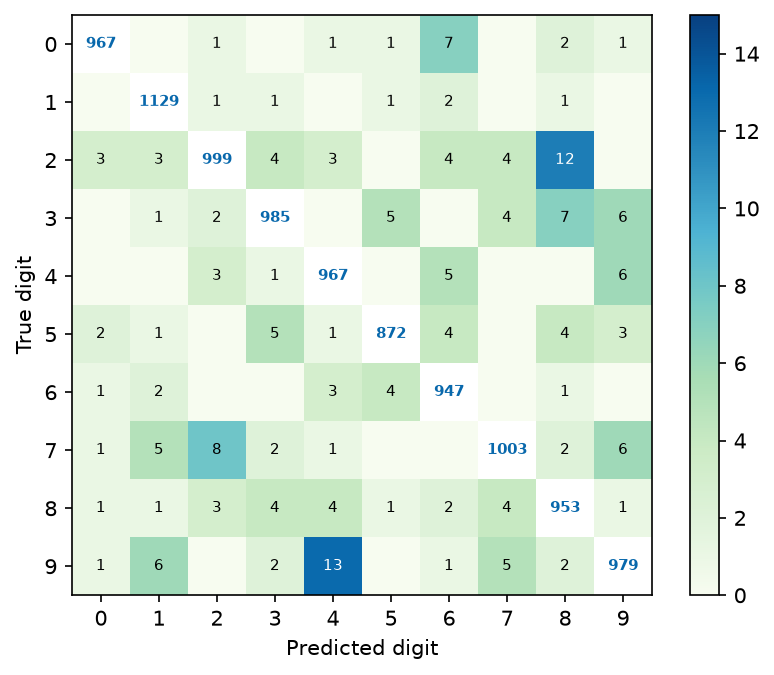

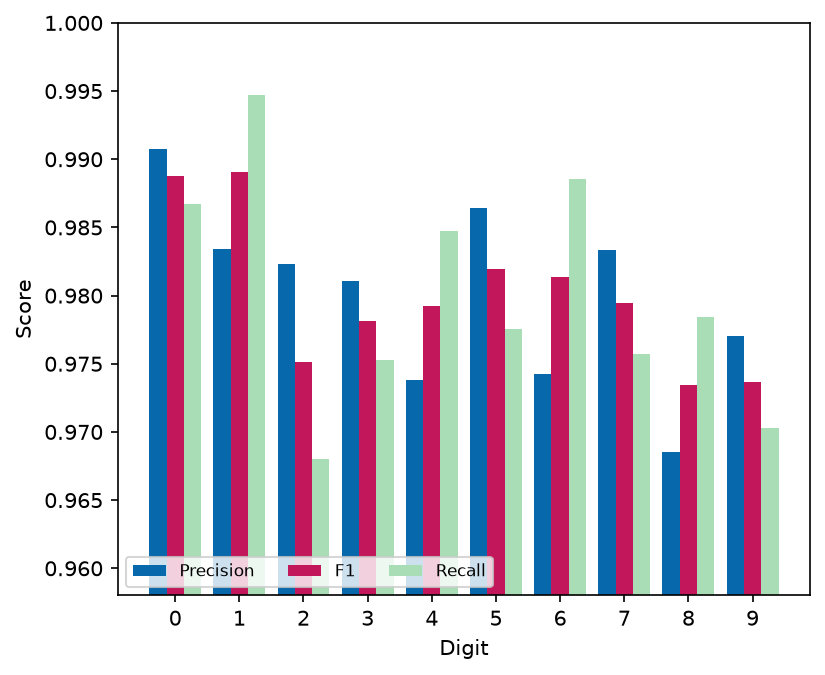

digit   precision  recall   F1
  0      0.9908    0.9867   0.9888
  1      0.9834    0.9947   0.9890
  2      0.9823    0.9680   0.9751
  3      0.9811    0.9752   0.9782
  4      0.9738    0.9847   0.9792
  5      0.9864    0.9776   0.9820
  6      0.9743    0.9885   0.9813
  7      0.9833    0.9757   0.9795
  8      0.9685    0.9784   0.9734
  9      0.9770    0.9703   0.9736
Vanligste feil (sant -> predikert: antall):
  9 -> 4: 13
  2 -> 8: 12
  7 -> 2: 8
  3 -> 8: 7
  0 -> 6: 7
  4 -> 9: 6


In [ ]:
C_PREC, C_F1, C_REC = "#0868ac", "#C2185B", "#a8ddb5"     # colors for the bars

def confusion_matrix_10(y_true, y_hat, n_classes=10):
    # C[i, j] = number of images with true digit i that were predicted as j
    C = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_hat):
        C[t, p] += 1
    return C

def precision_recall(C):
    diag = np.diag(C)
    return diag / C.sum(axis=0), diag / C.sum(axis=1)    # precision (columns), recall (rows)

def fig_confusion10(y_true, y_hat, fname_cm, fname_pr):
    C = confusion_matrix_10(y_true, y_hat)
    prec, rec = precision_recall(C)
    f1 = 2 * prec * rec / (prec + rec)
    print(f"Test accuracy: {np.trace(C) / C.sum():.4f}")

    # Figure (a): confusion matrix; color shows only the errors (the diagonal is blank)
    fig_a, ax_a = plt.subplots(figsize=(5.6, 4.6))
    off = C.astype(float).copy()
    np.fill_diagonal(off, np.nan)
    vmax = 15
    im = ax_a.imshow(off, cmap="GnBu", vmin=0, vmax=vmax)
    for i in range(10):
        for j in range(10):
            if i == j:
                ax_a.text(j, i, f"{C[i, j]}", ha="center", va="center",
                          fontsize=7, color=C_PREC, fontweight="bold")
            elif C[i, j] > 0:
                ax_a.text(j, i, f"{C[i, j]}", ha="center", va="center", fontsize=7,
                          color="white" if C[i, j] > 0.6 * vmax else "black")
    ax_a.set_xticks(range(10)); ax_a.set_yticks(range(10))
    ax_a.set_xlabel("Predicted digit"); ax_a.set_ylabel("True digit")
    cbar = fig_a.colorbar(im, ax=ax_a, fraction=0.046)
    cbar.set_ticks(np.arange(0, vmax + 1, 2))      # 0, 2, 4, ..., 14
    fig_a.tight_layout()
    fig_a.savefig(fname_cm)
    plt.show()

    # Figure (b): precision, F1, and recall for each digit
    fig_b, ax_b = plt.subplots(figsize=(5.6, 4.6))
    x = np.arange(10)
    w = 0.27                                       # three bars per digit
    ax_b.bar(x - w, prec, w, color=C_PREC, label="Precision")
    ax_b.bar(x,     f1,   w, color=C_F1,   label="F1")
    ax_b.bar(x + w, rec,  w, color=C_REC,  label="Recall")
    ax_b.set_ylim(min(prec.min(), rec.min(), f1.min()) - 0.01, 1.0)
    ax_b.set_xticks(range(10)); ax_b.set_xlabel("Digit")
    ax_b.set_ylabel("Score")
    ax_b.legend(fontsize=8, loc="lower left", ncol=3)
    fig_b.tight_layout()
    fig_b.savefig(fname_pr)
    plt.show()

    return C, prec, rec, f1

C, prec, rec, f1 = fig_confusion10(y_test, y_pred[BEST],
                                   "confusion10_best.pdf", "precision_recall_best.pdf")

print("digit   precision  recall   F1")
for d in range(10):
    print(f"  {d}      {prec[d]:.4f}    {rec[d]:.4f}   {f1[d]:.4f}")

# The six most common errors
C_off = C.copy()
np.fill_diagonal(C_off, 0)
largest = np.argsort(C_off, axis=None)[::-1][:6]    # indekser i den flate matrisen
print("Most common errors (true -> predicted: count):")
for k in largest:
    i, j = divmod(k, 10)
    print(f"  {i} -> {j}: {C_off[i, j]}")